# Del cuaderno al servicio: deriva, datos personales y un cuaderno con cinco defectos

**Avanzado · Jornada 3 · Bloque 3.4 · diapositivas deriva, viajes-personales, seudonimizar y ejercicio-produccion**

¿Qué separa un cuaderno que funciona de un modelo que se puede operar y gobernar? La deriva de la telemetría por el cambio de proveedor, los viajes que delatan dónde vive cada usuario y el ejercicio de revisar un cuaderno «de producción» y redactar su ficha de modelo.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## La pregunta

¿Qué hace falta para que un modelo siga siendo válido dentro de seis meses? Tres piezas de BiciCiudad:

1. **La deriva:** un cambio de proveedor movió la telemetría sin que nadie avisara.
2. **Los viajes como datos personales:** origen, destino y hora delatan dónde vive y trabaja cada
   usuario, aunque no lleven nombre.
3. **El ejercicio:** un cuaderno que alguien quiere llevar a producción mañana. Funciona y da una lista
   razonable, pero tiene cinco defectos que lo impiden. Encontradlos y redactad su ficha de modelo.

> **Mensaje clave del bloque:** el modelo es el 10 % del trabajo; el otro 90 % es que alguien confíe en
> él el año que viene.

## 1. La deriva: el proveedor nuevo movió la telemetría sin avisar

Las bicis mandan un mensaje cada hora. El 15 de abril de 2026 cambió el proveedor de conectividad, un
cambio de contrato que nadie del equipo de datos conocía. `telemetria/intervalo_mensajes_deriva.csv`
tiene el histograma del intervalo entre dos mensajes seguidos de una misma bici, en marzo y en mayo, en
tramos de 30 s entre 3.000 y 4.200 s (50 y 70 minutos), más dos tramos abiertos: menos de 3.000 s y más
de 4.200 s (un mensaje perdido).

In [2]:
%matplotlib inline
# Los gráficos, dentro del cuaderno; las tablas, con coma decimal.
pd.set_option("display.float_format", lambda x: estilo.num(x, 2))
histograma = pd.read_csv(DATOS / "telemetria" / "intervalo_mensajes_deriva.csv")
histograma.head()

,periodo,desde_s,hasta_s,intervalos
0,antes (marzo de 2026),NaN,"3.000,00",0
1,antes (marzo de 2026),"3.000,00","3.030,00",0
2,antes (marzo de 2026),"3.030,00","3.060,00",0
3,antes (marzo de 2026),"3.060,00","3.090,00",0
4,antes (marzo de 2026),"3.090,00","3.120,00",0


In [3]:
filas = []
for periodo, tramos in histograma.groupby("periodo"):
    total = tramos["intervalos"].sum()
    centrales = tramos.dropna(subset=["desde_s", "hasta_s"])  # los tramos de 30 s
    centro = centrales["desde_s"] + 15                         # punto medio de cada tramo
    peso = centrales["intervalos"]
    media = (peso * centro).sum() / peso.sum()
    desviacion = np.sqrt((peso * (centro - media) ** 2).sum() / peso.sum())
    perdidos = tramos.loc[tramos["desde_s"] == 4200, "intervalos"].sum()
    filas.append({"periodo": periodo, "intervalos": total, "media_s": media,
                  "desviacion_tipica_s": desviacion, "perdidos_pct": 100 * perdidos / total})
deriva = pd.DataFrame(filas).set_index("periodo")
deriva

,intervalos,media_s,desviacion_tipica_s,perdidos_pct
periodo,,,,
antes (marzo de 2026),1458602,"3.600,74","14,98","0,10"
después (mayo de 2026),1441033,"3.600,53","127,82","1,59"


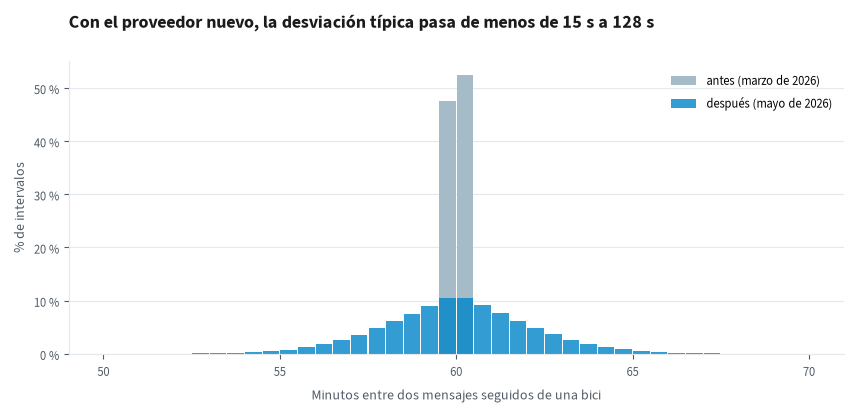

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for periodo, color, alfa in (("antes (marzo de 2026)", estilo.GRIS, 1), ("después (mayo de 2026)", estilo.AZUL, 0.8)):
    tramos = histograma[histograma["periodo"] == periodo].dropna(subset=["desde_s", "hasta_s"])
    pct = 100 * tramos["intervalos"] / histograma.loc[histograma["periodo"] == periodo, "intervalos"].sum()
    ax.bar((tramos["desde_s"] + 15) / 60, pct, width=0.47, color=color, alpha=alfa, label=periodo)
ax.set_xticks([50, 55, 60, 65, 70])
ax.set_xlabel("Minutos entre dos mensajes seguidos de una bici")
ax.set_ylabel("% de intervalos")
estilo.formato_eje(ax, "y", 0, " %")
ax.legend()
ax.set_title(f"Con el proveedor nuevo, la desviación típica pasa de menos de 15 s "
             f"a {estilo.num(deriva['desviacion_tipica_s'].iloc[1])} s")
plt.show()

**Ojo con marzo.** Con tramos de 30 s, el histograma no distingue desviaciones menores de unos 15 s:
casi todo marzo cae en los dos tramos del centro, y la cuenta de arriba da 15 aunque la desviación real
sea menor. Lo honrado es decir «de menos de 15 s». La de mayo, 128 s, sí se mide bien.

Ningún sistema dio una alarma: los datos siguen llegando y los cuadros de mando se siguen pintando. Pero
cualquier modelo que cuente huecos, como el informe de calidad de la Jornada 1, ahora ve bicis «con
problemas» que solo tienen un proveedor más lento. Eso es **deriva de datos**. La de Google Flu Trends es
**deriva de concepto**: las entradas parecen iguales, pero su relación con lo que se predice ha cambiado.

Vigilarla no es difícil: basta escribir el límite antes de que pase nada. Mañana, con gráficos de control,
se hace con rigor.

In [5]:
LIMITE_DESVIACION_S = 30   # ← desviación típica del intervalo a partir de la cual avisamos
LIMITE_PERDIDOS_PCT = 0.5  # ← % de mensajes perdidos a partir del cual avisamos

for periodo, fila in deriva.iterrows():
    aviso = fila["desviacion_tipica_s"] > LIMITE_DESVIACION_S or fila["perdidos_pct"] > LIMITE_PERDIDOS_PCT
    print(f"{periodo}: desviación {estilo.num(fila['desviacion_tipica_s'])} s, "
          f"perdidos {estilo.num(fila['perdidos_pct'], 1)} % → {'AVISO' if aviso else 'normal'}")

antes (marzo de 2026): desviación 15 s, perdidos 0,1 % → normal
después (mayo de 2026): desviación 128 s, perdidos 1,6 % → AVISO


## 2. Origen, destino y hora delatan dónde vive cada usuario

**Trampa: «son datos anónimos».** `viajes_muestra/viajes.csv` tiene los viajes de septiembre de 2026 de
una muestra de usuarios. No hay nombres: cada usuario es un seudónimo (un código sacado de su
identificador). Empezamos por el usuario de la diapositiva.

In [6]:
viajes = pd.read_csv(DATOS / "viajes_muestra" / "viajes.csv")
print(f"{estilo.num(len(viajes))} viajes de {estilo.num(viajes['usuario'].nunique())} usuarios seudónimos")

ejemplo = viajes[viajes["usuario"] == "U-b51796d801"].copy()
ejemplo["hora_local"] = bici.hora_local(ejemplo["salida_utc"])
# Sus dos estaciones más frecuentes, contando orígenes y destinos.
frecuentes = pd.concat([ejemplo["estacion_origen"], ejemplo["estacion_destino"]]).value_counts()
dos = list(frecuentes.index[:2])
tocan = (ejemplo["estacion_origen"].isin(dos) | ejemplo["estacion_destino"].isin(dos)).mean()
print(f"{len(ejemplo)} viajes en septiembre; el {estilo.num(100 * tocan)} % empieza o acaba en {dos[0]} o {dos[1]}")
for origen in dos:
    salidas = ejemplo.loc[ejemplo["estacion_origen"] == origen, "hora_local"]
    minutos = (salidas.dt.hour * 60 + salidas.dt.minute).median()
    print(f"  Sale de {origen} hacia las {int(minutos // 60)}:{int(minutos % 60):02d} (mediana)")

19.294 viajes de 943 usuarios seudónimos
45 viajes en septiembre; el 89 % empieza o acaba en E-01 o E-09
  Sale de E-01 hacia las 8:01 (mediana)
  Sale de E-09 hacia las 17:56 (mediana)


Sale de E-01 hacia las 8:00 y vuelve desde E-09 por la tarde: casa junto a E-01, trabajo junto a E-09.
Sin su nombre. ¿Pasa solo con este usuario? Aplicamos la misma regla a todos: en los laborables por la
mañana, la estación de la que más sale cada usuario es «su casa» y a la que más va, «su trabajo».

In [7]:
HORAS_MANANA = (6, 9)  # ← franja de salida (hora local) que tomamos como «ir al trabajo»
MIN_VIAJES = 3         # ← viajes de mañana necesarios para atreverse a deducir

viajes["salida_local"] = bici.hora_local(viajes["salida_utc"])
manana = viajes[(viajes["salida_local"].dt.dayofweek < 5)
                & viajes["salida_local"].dt.hour.between(*HORAS_MANANA)]
deducido = manana.groupby("usuario").agg(
    viajes_manana=("viaje_id", "size"),
    casa=("estacion_origen", lambda s: s.mode().iloc[0]),
    trabajo=("estacion_destino", lambda s: s.mode().iloc[0]),
)
deducido = deducido[deducido["viajes_manana"] >= MIN_VIAJES]
print(f"Casa y trabajo deducidos para {estilo.num(len(deducido))} de "
      f"{estilo.num(viajes['usuario'].nunique())} usuarios")
deducido.head()

Casa y trabajo deducidos para 624 de 943 usuarios


,viajes_manana,casa,trabajo
usuario,,,
U-011bc44f4b,15,E-32,E-11
U-0170dc1f79,16,E-15,E-28
U-023374303c,19,E-01,E-14
U-03029ad090,11,E-01,E-08
U-03b4cb4919,10,E-12,E-25


Con una línea de `groupby`, dos de cada tres usuarios quedan ubicados en casa y en el trabajo. Cualquiera
que conozca a alguien que vive junto a una estación y trabaja junto a otra lo tiene identificado. Es el
mapa de Strava y el 87 % de Sweeney del curso conceptual, ahora con bicis: **los viajes con origen,
destino y hora son datos personales, aunque no lleven nombre.** Y seudonimizar no es anonimizar: el
RGPD (considerando 26) dice que lo seudonimizado sigue siendo dato personal.

**Minimización.** Para prever la demanda por estación no hace falta saber quién viajó, ni el minuto
exacto: basta el recuento por estación y hora. Lo que no se guarda no se puede filtrar.

In [8]:
demanda = (viajes.assign(hora=viajes["salida_local"].dt.hour)
           .groupby(["estacion_origen", "hora"]).size().rename("viajes").reset_index())
demanda.head()  # sin usuario, sin minuto: sirve para la demanda y no delata a nadie

,estacion_origen,hora,viajes
0,E-01,6,3
1,E-01,7,232
2,E-01,8,234
3,E-01,9,4
4,E-01,10,18


## 3. Ejercicio (en parejas, 25 min): cinco defectos en un cuaderno «de producción»

Un compañero ha preparado este cuaderno para elegir a qué usuarios se les manda la oferta del abono.
Funciona: lee los viajes individuales de septiembre y saca su lista sin errores. Quiere ponerlo en
producción mañana, para que se ejecute cada mes. Tiene **cinco defectos** sembrados que lo impiden. No son
errores de cálculo: el cuaderno funciona y da una lista razonable.

**Parte 1 (unos 12 minutos):** encontrad los cinco defectos. **Parte 2 (el resto):** redactad su ficha de
modelo de una página. Lo que no sepáis rellenar también es información: si no hay dueño, escribid «sin dueño».

Así os lo entregan, tal cual:

```python
# Campaña abono septiembre — versión final (buena)

import hashlib
import pandas as pd

viajes = pd.read_csv("C:/Users/pc-analitica-03/Escritorio/BiciCiudad/viajes_septiembre.csv")

# muestra para que vaya más rápido
muestra = viajes.sample(frac=0.5)

# viajes con tarifa ocasional de cada usuario
ocasionales = muestra[muestra["tarifa"] == "ocasional"]
viajes_por_usuario = ocasionales.groupby("usuario").size()

# candidatos a la oferta del abono
candidatos = viajes_por_usuario[viajes_por_usuario >= 3].index

# número de cliente, para que marketing les mande la oferta
SAL = "biciciudad-curso-2026"
cliente_de = {"U-" + hashlib.sha256(f"{SAL}-{i}".encode()).hexdigest()[:10]: i for i in range(5000)}
lista_envio = pd.DataFrame({"usuario": candidatos, "cliente": [cliente_de[u] for u in candidatos]})

print(len(lista_envio), "clientes recibirán la oferta")
lista_envio.head()
```

Para revisarlo, ejecutadlo. Esta es una copia del cuaderno que funciona en Colab; podéis ejecutarla
tantas veces como queráis y cambiar lo que os parezca.

In [9]:
# Campaña abono septiembre — versión final (buena)

import hashlib
import pandas as pd

# Para ejecutarlo aquí, esta línea lee los datos del curso; el resto es idéntico al original.
viajes = pd.read_csv(DATOS / "viajes_muestra" / "viajes.csv")

# muestra para que vaya más rápido
muestra = viajes.sample(frac=0.5)

# viajes con tarifa ocasional de cada usuario
ocasionales = muestra[muestra["tarifa"] == "ocasional"]
viajes_por_usuario = ocasionales.groupby("usuario").size()

# candidatos a la oferta del abono
candidatos = viajes_por_usuario[viajes_por_usuario >= 3].index

# número de cliente, para que marketing les mande la oferta
SAL = "biciciudad-curso-2026"
cliente_de = {"U-" + hashlib.sha256(f"{SAL}-{i}".encode()).hexdigest()[:10]: i for i in range(5000)}
lista_envio = pd.DataFrame({"usuario": candidatos, "cliente": [cliente_de[u] for u in candidatos]})

print(len(lista_envio), "clientes recibirán la oferta")
lista_envio.head()

86 clientes recibirán la oferta


,usuario,cliente
0,U-01232a2443,77
1,U-0392041489,185
2,U-04c326a064,240
3,U-08cde428a6,937
4,U-0cd816ca93,481


In [10]:
# Parte 1. Los cinco defectos: una frase cada uno, con la línea donde está y por qué impide
# llevarlo a producción.
defectos = [
    "",  # ← COMPLETAD
    "",
    "",
    "",
    "",
]
for numero, defecto in enumerate(defectos, start=1):
    print(numero, defecto or "…")

1 …
2 …
3 …
4 …
5 …


In [11]:
# Espacio para vuestras pruebas: ejecutad aquí trozos del cuaderno, comparad resultados…

Si programáis: reescribid el cuaderno sin los defectos en la celda siguiente (los parámetros arriba, con
`# ←`). Ejecutadlo dos veces: tiene que salir lo mismo.

In [12]:
# COMPLETAD (opcional): el cuaderno corregido.

### Parte 2. La ficha de modelo, en una página

Haced doble clic en esta celda y rellenadla (en Colab se edita como texto).

| Apartado | Lo que pide | Vuestra respuesta |
| --- | --- | --- |
| **Qué decide y para quién** | Qué decisión alimenta y quién la usa | … |
| **Dueño, con nombre** | Una persona, no un departamento | … |
| **Datos** | Fuente, versión y datos personales | … |
| **Validación** | Contra qué rival y con qué resultado | … |
| **Vigilancia** | Qué se mira y cada cuánto | … |
| **Retirada** | Cuándo se apaga (escrito el primer día) | … |

## Qué os lleváis

- **Si no podéis repetirlo, no podéis defenderlo:** datos versionados, semillas, entorno fijado y código
  en un repositorio.
- **El mundo cambia debajo del modelo.** Un cambio de proveedor movió la telemetría sin avisar; se vigila
  con límites escritos antes, y mañana con gráficos de control.
- **Origen, destino y hora son datos personales.** Seudonimizar no es anonimizar; minimizad lo que guardáis
  y guardad la clave fuera del código.
- **Todo modelo necesita un dueño con nombre** y un criterio de retirada escrito el primer día.
- **El cuadro de mando enseña; no calcula.**

> El modelo es el 10 % del trabajo; el otro 90 % es que alguien confíe en él el año que viene.